<a href="https://colab.research.google.com/github/DeepFluxion/2026_2_IBMEC_PROG_ANALISE_DADOS/blob/main/notebooks/Aula_2026_10_26_Projeto_Pratico_Melbourne.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://www.institutomillenium.org.br/wp-content/uploads/2024/02/logo-ibmec-topo-rj-450x150.png.webp" width=300>

# Programação para Análise de Dados

## Aula 4 — Projeto Prático: Imóveis de Melbourne

**Duração:** 1h50 · **Dataset:** `melb_data.csv` (13.580 imóveis vendidos em Melbourne, Austrália)

| Bloco | Tema | Tempo |
|---|---|---|
| 1 | Preparação e carregamento dos dados | 10 min |
| 2 | Limpeza dos dados | 20 min |
| 3 | Explorando os dados | 15 min |
| 4 | **Regressão:** prever o preço (Aula 1) | 20 min |
| 5 | **KNN:** imóvel caro ou barato? (Aula 2) | 20 min |
| 6 | **PCA + K-means:** perfis de imóveis (Aula 3) | 20 min |
| 7 | Exercícios e fechamento | 5 min |

> **Objetivo:** mostrar como as técnicas das Aulas 1 a 3 se encaixam em **um projeto completo**. Os blocos 4, 5 e 6 repetem os passos que você já conhece, agora em dados reais e "sujos". Este roteiro serve de modelo para o **seu** projeto.

> **Antes de começar:** coloque o arquivo `melb_data.csv` **na mesma pasta** deste notebook. (No Google Colab: clique no ícone de pasta à esquerda e arraste o arquivo para lá.)

# 🧰 Bloco 1 — Preparação e carregamento (10 min)

## O roteiro de um projeto de dados

| Etapa | Pergunta | Onde aprendemos |
|---|---|---|
| 1. Carregar | Como são os dados? | pandas |
| 2. Limpar | Há valores faltando ou absurdos? | pandas |
| 3. Explorar | O que os gráficos e as correlações mostram? | Aula 1 |
| 4. Modelar (regressão) | Dá para **prever** o preço? | Aula 1 |
| 5. Modelar (classificação) | Dá para dizer se o imóvel é **caro**? | Aula 2 |
| 6. Agrupar | Existem **perfis** de imóveis? | Aula 3 |

## Sobre o dataset
Cada linha é um **imóvel vendido** em Melbourne. Usaremos estas colunas:

| Coluna original | Nome que usaremos | Significado |
|---|---|---|
| `Price` | `preco` | preço de venda (dólares australianos) |
| `Rooms` | `quartos` | número de quartos |
| `Bathroom` | `banheiros` | número de banheiros |
| `Car` | `vagas` | vagas de garagem |
| `Distance` | `distancia_km` | distância até o centro da cidade (km) |
| `Landsize` | `terreno_m2` | tamanho do terreno (m²) |

### Importando as bibliotecas

Importamos tudo o que usaremos nas Aulas 1 a 3, de uma vez.

**🔍 Linha a linha**

- As quatro primeiras linhas carregam numpy, pandas, matplotlib e seaborn.
- `train_test_split` e `StandardScaler`: separar treino/teste e padronizar (Aulas 1 e 2).
- `LinearRegression`, `KNeighborsClassifier`, `PCA`, `KMeans`: os quatro modelos das Aulas 1 a 3.
- O bloco `from sklearn.metrics import (...)` traz as métricas de regressão (R², MAE, RMSE) e de classificação (acurácia, matriz de confusão, precisão e recall). Os parênteses permitem quebrar a lista em duas linhas.
- As linhas finais configuram avisos, estilo e tamanho dos gráficos e guardam 4 cores.

In [1]:
import numpy as np                                    # numpy: contas com números
import pandas as pd                                   # pandas: tabelas de dados (DataFrame)
import matplotlib.pyplot as plt                       # matplotlib: gráficos
import seaborn as sns                                 # seaborn: heatmap
from sklearn.model_selection import train_test_split  # separa os dados em treino e teste
from sklearn.preprocessing import StandardScaler      # coloca as variáveis na mesma escala
from sklearn.linear_model import LinearRegression     # regressão linear (Aula 1)
from sklearn.neighbors import KNeighborsClassifier    # KNN (Aula 2)
from sklearn.decomposition import PCA                 # PCA (Aula 3)
from sklearn.cluster import KMeans                    # K-means (Aula 3)
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,    # métricas de regressão
                             accuracy_score, confusion_matrix, precision_score, recall_score)   # métricas de classificação
import warnings                                       # avisos do Python
warnings.filterwarnings('ignore')                     # esconde avisos para a saída ficar limpa

sns.set_theme(style='whitegrid')                      # estilo visual dos gráficos
plt.rcParams['figure.figsize'] = (7, 4.5)             # tamanho padrão dos gráficos

AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores que usaremos
print('Ambiente pronto!')                             # mensagem de confirmação

Ambiente pronto!


### Carregando o arquivo CSV

Um arquivo **CSV** é uma tabela em texto; o pandas lê com `read_csv`.

**🔍 Linha a linha**

- `pd.read_csv('melb_data.csv')`: lê o arquivo e cria um DataFrame. Se der `FileNotFoundError`, o arquivo não está na mesma pasta do notebook.
- `df_bruto.shape`: (13580 linhas, 21 colunas).
- `.columns.tolist()`: transforma os nomes das colunas em uma lista simples.
- `.head()`: mostra o começo da tabela. O nome **bruto** lembra que esses dados ainda **não foram limpos**.

In [2]:
# Endereço dos dados no github
url = "https://raw.githubusercontent.com/DeepFluxion/2026_2_IBMEC_PROG_ANALISE_DADOS/refs/heads/main/datasets/melb_data.csv"
df_bruto = pd.read_csv(url)                # lê o arquivo (que deve estar na mesma pasta do notebook)

print('Linhas e colunas:', df_bruto.shape)             # (número de imóveis, número de colunas)
print()                                                # linha em branco
print('Colunas do arquivo:')                           # título
print(df_bruto.columns.tolist())                       # lista com os nomes de todas as colunas
df_bruto.head()                                        # mostra as 5 primeiras linhas

Linhas e colunas: (13580, 21)

Colunas do arquivo:
['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude', 'Regionname', 'Propertycount']


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


# 🧹 Bloco 2 — Limpeza dos dados (20 min)

Dados reais quase nunca estão prontos para modelar. Vamos fazer **quatro** tarefas simples:

1. **Selecionar** as colunas que interessam e dar nomes claros.
2. **Tratar valores ausentes** (células vazias).
3. **Remover valores extremos** (*outliers*) que distorcem as contas.
4. **Conferir** o resultado.

> **Decisão didática:** usamos só colunas **numéricas**. Colunas com muitos ausentes (como `BuildingArea`, 47% vazia, e `YearBuilt`, 40% vazia) foram **deixadas de fora**.

### Passo 1 — Selecionar colunas e renomear

Escolhemos 6 colunas do arquivo e trocamos os nomes por nomes em português.

**🔍 Linha a linha**

- `colunas_originais = [...]`: lista com os nomes (exatamente como no arquivo) das colunas que vamos usar.
- `df_bruto[colunas_originais]`: seleciona só essas colunas. `.copy()` cria uma **cópia**, assim mexer em `df` não altera `df_bruto`.
- `df.columns = [...]`: troca os nomes das colunas; a nova lista precisa ter **a mesma ordem e o mesmo tamanho**.

In [3]:
colunas_originais = ['Price', 'Rooms', 'Bathroom', 'Car', 'Distance', 'Landsize']   # colunas que queremos manter
df = df_bruto[colunas_originais].copy()                # cria uma nova tabela só com essas colunas (copy = cópia independente)
df.columns = ['preco', 'quartos', 'banheiros', 'vagas', 'distancia_km', 'terreno_m2']   # novos nomes, na mesma ordem
print('Formato:', df.shape)                            # linhas e colunas agora
df.head()                                              # primeiras linhas

Formato: (13580, 6)


,preco,quartos,banheiros,vagas,distancia_km,terreno_m2
0,1480000.0,2,1.0,1.0,2.5,202.0
1,1035000.0,2,1.0,0.0,2.5,156.0
2,1465000.0,3,2.0,0.0,2.5,134.0
3,850000.0,3,2.0,1.0,2.5,94.0
4,1600000.0,4,1.0,2.0,2.5,120.0


### Passo 2 — Valores ausentes

Modelos do scikit-learn **não aceitam células vazias**. Primeiro contamos, depois removemos.

**🔍 Linha a linha**

- `df.isnull()`: tabela de verdadeiro/falso (True onde a célula está vazia). `.sum()` conta os True de cada coluna.
- `len(df)`: número de linhas. Guardamos o valor antes para comparar depois.
- `df.dropna()`: **remove** as linhas que tenham qualquer célula vazia. É a solução mais simples; a perda é pequena (poucas linhas).
- `\n` dentro do texto: pula uma linha.

In [4]:
print('Valores ausentes por coluna:')                  # título
print(df.isnull().sum())                               # conta as células vazias de cada coluna

linhas_antes = len(df)                                 # guarda o número de linhas antes da limpeza
df = df.dropna()                                       # remove as linhas que têm alguma célula vazia
print(f'\nLinhas removidas: {linhas_antes - len(df)}')  # quantas linhas foram removidas
print(f'Linhas restantes: {len(df)}')                  # quantas sobraram

Valores ausentes por coluna:
preco            0
quartos          0
banheiros        0
vagas           62
distancia_km     0
terreno_m2       0
dtype: int64

Linhas removidas: 62
Linhas restantes: 13518


### Passo 3 — Valores extremos (outliers)

Olhe o `describe()`: o maior terreno tem 433.014 m², enquanto 75% dos imóveis têm até ≈ 650 m². É um valor absurdo (provável erro).

**🔍 Linha a linha**

- `df['terreno_m2'].max()`: o maior valor da coluna.
- `(df['terreno_m2'] > 2000)`: gera verdadeiro/falso para cada imóvel; `.sum()` conta os verdadeiros.
- `df[df['terreno_m2'] <= 2000]`: **filtro**: fica só com as linhas em que a condição é verdadeira.
- O limite de 2000 m² é uma **escolha** nossa (pode ser outra). O importante é documentar a decisão.
- Terrenos com 0 m² **foram mantidos**: são apartamentos, que não têm terreno próprio.

In [5]:
print('Maior terreno:', df['terreno_m2'].max(), 'm²')  # valor máximo do terreno
print('Terrenos acima de 2000 m²:', (df['terreno_m2'] > 2000).sum())   # quantos imóveis passam de 2000 m²

df = df[df['terreno_m2'] <= 2000]                      # mantém só os imóveis com terreno até 2000 m²
print('Linhas restantes:', len(df))                    # quantas sobraram

Maior terreno: 433014.0 m²
Terrenos acima de 2000 m²: 235
Linhas restantes: 13283


### Passo 4 — Conferindo os dados limpos

O `describe()` resume cada coluna: contagem, média, desvio, mínimo, quartis e máximo.

**🔍 Linha a linha**

- `df.describe()`: resumo de cada coluna numérica (count, mean, std, min, 25%, 50%, 75%, max).
- Agora não há ausentes (todas as colunas têm o mesmo `count`) e o terreno máximo é 2000.

In [6]:
print(df.describe().round(1))                          # resumo estatístico com 1 casa decimal

           preco  quartos  banheiros    vagas  distancia_km  terreno_m2
count    13283.0  13283.0    13283.0  13283.0       13283.0     13283.0
mean   1078763.4      3.0        1.5      1.6          10.2       427.5
std     637113.7      1.0        0.7      1.0           5.8       311.8
min      85000.0      1.0        0.0      0.0           0.0         0.0
25%     650000.0      2.0        1.0      1.0           6.3       173.0
50%     906000.0      3.0        1.0      2.0           9.3       427.0
75%    1332500.0      4.0        2.0      2.0          13.0       647.0
max    9000000.0     10.0        8.0     10.0          47.4      2000.0


# 🔎 Bloco 3 — Explorando os dados (15 min)

Antes de modelar, **olhe os dados**: a distribuição do preço e as correlações (Aula 1).

### Como se distribui o preço?

Um histograma agrupa os preços em "faixas" e conta quantos imóveis há em cada uma.

**🔍 Linha a linha**

- `df['preco'] / 1_000_000`: divide por 1 milhão, para o eixo ficar legível (o `_` nos números é só separador visual).
- `bins=40`: número de faixas (barras) do histograma.
- Leitura: a maioria dos imóveis custa entre 0,5 e 1,5 milhão; poucos custam muito mais (cauda longa à direita).

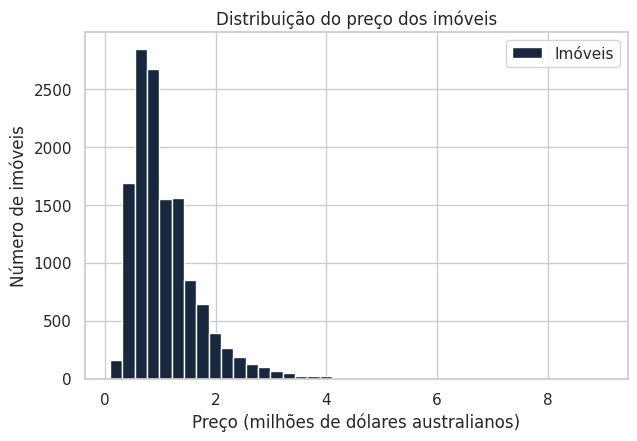

In [7]:
plt.hist(df['preco'] / 1_000_000, bins=40, color=AZUL, label='Imóveis')   # histograma; preço em milhões
plt.title('Distribuição do preço dos imóveis')         # título
plt.xlabel('Preço (milhões de dólares australianos)')  # eixo x
plt.ylabel('Número de imóveis')                        # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### Heatmap de correlação

Quais variáveis mais se relacionam com o preço?

**🔍 Linha a linha**

- Igual ao heatmap da Aula 1: `df.corr()` calcula e `sns.heatmap` desenha.
- Leitura: o preço se relaciona **positivamente** com quartos (≈ 0,49), banheiros (≈ 0,47) e terreno (≈ 0,31), e **negativamente** com a distância ao centro (≈ −0,17).
- Repare também que `quartos` e `banheiros` são correlacionados entre si (≈ 0,59): trazem informação parecida.

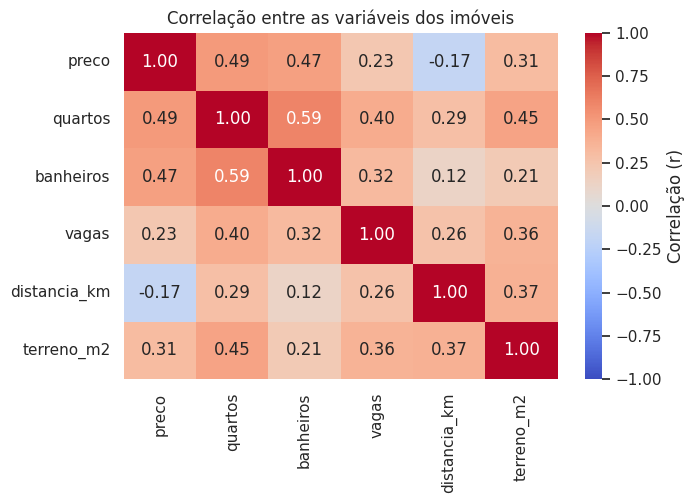

In [8]:
corr = df.corr()                                       # matriz de correlação de todas as colunas
sns.heatmap(corr, annot=True, fmt='.2f',               # escreve os valores nas células
            cmap='coolwarm', vmin=-1, vmax=1,          # cores de -1 a 1
            cbar_kws={'label': 'Correlação (r)'})      # legenda da barra de cores
plt.title('Correlação entre as variáveis dos imóveis') # título
plt.show()                                             # exibe

### Distância ao centro × preço

Um gráfico de dispersão com muitos pontos precisa de **transparência**.

**🔍 Linha a linha**

- `alpha=0.2`: pontos 80% transparentes; onde há muitos pontos juntos, a cor fica mais forte.
- `s=10`: pontos pequenos, para não encobrir uns aos outros.
- Leitura: imóveis mais perto do centro tendem a ser mais caros, mas há **muita variação**: a distância sozinha não explica o preço.

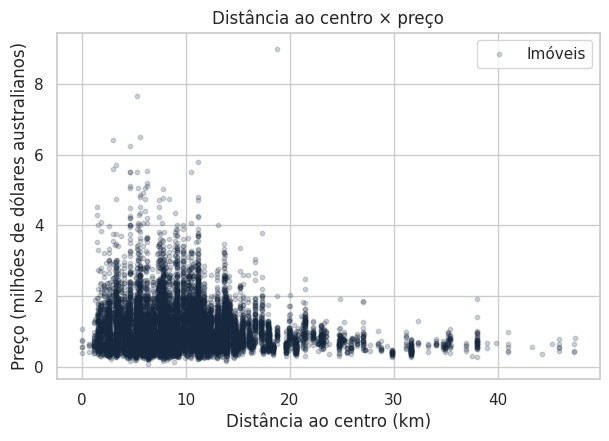

In [9]:
plt.scatter(df['distancia_km'], df['preco'] / 1_000_000,   # x = distância, y = preço em milhões
            color=AZUL, alpha=0.2, s=10, label='Imóveis')  # alpha = transparência; s = tamanho dos pontos
plt.title('Distância ao centro × preço')               # título
plt.xlabel('Distância ao centro (km)')                 # eixo x
plt.ylabel('Preço (milhões de dólares australianos)')  # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

# 📈 Bloco 4 — Regressão: prever o preço (20 min)

**Pergunta:** dá para prever o `preco` a partir de quartos, banheiros, vagas, distância e terreno?

Mesmos **7 passos** da Aula 1 (regressão múltipla):

| Passo | O que fazer |
|---|---|
| 1 | Separar X e y |
| 2 | Dividir em treino e teste |
| 3 | Criar o modelo |
| 4 | Treinar (`fit`) |
| 5 | Ver os coeficientes |
| 6 | Prever (`predict`) |
| 7 | Avaliar (R², MAE, RMSE) |

### Passos 1 a 4 — Separar, dividir, criar e treinar

X é todo o resto; y é o preço.

**🔍 Linha a linha**

- `colunas_x = [...]`: lista das colunas explicativas; `df[colunas_x]` seleciona todas de uma vez.
- `y = df['preco']`: o alvo. Note que o preço **não** entra em X.
- `train_test_split(..., test_size=0.2, random_state=42)`: separa 20% dos imóveis para o teste (os "nunca vistos").
- `LinearRegression()` e `.fit(...)`: exatamente como na Aula 1.

In [10]:
colunas_x = ['quartos', 'banheiros', 'vagas', 'distancia_km', 'terreno_m2']   # variáveis explicativas
X = df[colunas_x]                                      # passo 1: X = as 5 colunas explicativas
y = df['preco']                                        # passo 1: y = o que queremos prever

X_treino, X_teste, y_treino, y_teste = train_test_split(   # passo 2: divide em treino e teste
    X, y, test_size=0.2, random_state=42)              # 20% para teste; semente fixa

modelo_preco = LinearRegression()                      # passo 3: cria o modelo
modelo_preco.fit(X_treino, y_treino)                   # passo 4: treina com os dados de treino
print('Modelo treinado com', len(X_treino), 'imóveis') # confirmação

Modelo treinado com 10626 imóveis


### Passo 5 — Coeficientes

Quanto cada característica "vale" no preço, mantendo as outras constantes?

**🔍 Linha a linha**

- `modelo_preco.coef_`: um coeficiente por variável, na mesma ordem de `colunas_x`.
- `{valor:,.0f}`: formata o número com separador de milhar e **sem** casas decimais.
- `to_string(index=False)`: imprime a tabela sem a coluna de índices.

In [11]:
tabela_coef = pd.DataFrame({                           # tabela de coeficientes
    'variavel': colunas_x,                             # nome de cada variável
    'coeficiente': modelo_preco.coef_.round(0)         # efeito no preço (em dólares)
})
print(f'Intercepto: {modelo_preco.intercept_:,.0f}')   # b0, com separador de milhar
print(tabela_coef.to_string(index=False))              # mostra a tabela sem o índice

Intercepto: 264,021
    variavel  coeficiente
     quartos     210307.0
   banheiros     246848.0
       vagas      24885.0
distancia_km     -43230.0
  terreno_m2        508.0


### 🗣️ Interpretando (mantendo as demais variáveis constantes)

- **quartos ≈ +210 mil:** cada quarto a mais soma ≈ 210 mil dólares ao preço previsto.
- **banheiros ≈ +247 mil:** cada banheiro a mais soma ≈ 247 mil.
- **distancia_km ≈ −43 mil:** cada km mais longe do centro **reduz** ≈ 43 mil.
- **terreno_m2 ≈ +508:** cada m² de terreno soma ≈ 508 dólares (parece pouco, mas 100 m² = ≈ 51 mil).
- **vagas:** efeito pequeno, depois de considerar as demais variáveis.

> Lembre: coeficientes mostram **associação nos dados**, não "causa".

### Passos 6 e 7 — Prever e avaliar

Medimos a qualidade **no teste**.

**🔍 Linha a linha**

- `modelo_preco.predict(X_teste)`: o preço previsto de cada imóvel do teste.
- `r2_score`, `mean_absolute_error`, `mean_squared_error`: as mesmas métricas da Aula 1.
- **Leitura:** R² ≈ 0,43: o modelo explica menos da metade da variação do preço. O erro médio é ≈ 338 mil dólares. **Faltam informações importantes** (localização, tipo do imóvel, estado de conservação...), que não estão neste modelo.

In [12]:
y_prev = modelo_preco.predict(X_teste)                 # passo 6: previsões para os imóveis do teste

r2 = r2_score(y_teste, y_prev)                         # R²: parte da variação explicada
mae = mean_absolute_error(y_teste, y_prev)             # MAE: erro médio absoluto
rmse = np.sqrt(mean_squared_error(y_teste, y_prev))    # RMSE: raiz do erro quadrático médio

print(f'R²   = {r2:.3f}')                              # qualidade geral
print(f'MAE  = {mae:,.0f} dólares')                    # erro médio
print(f'RMSE = {rmse:,.0f} dólares')                   # erro que pune mais os erros grandes

R²   = 0.428
MAE  = 338,483 dólares
RMSE = 485,378 dólares


### Gráfico: real × previsto

Quanto mais perto da diagonal, melhor a previsão.

**🔍 Linha a linha**

- Igual ao gráfico da Aula 1; aqui dividimos por 1 milhão para o eixo ficar legível.
- `plt.xlim(0, 5)` e `plt.ylim(-0.5, 5)`: limitam os eixos (poucos imóveis passam de 5 milhões).
- Leitura: os pontos formam uma nuvem larga em torno da diagonal: o modelo acerta a tendência, mas erra bastante em cada imóvel.

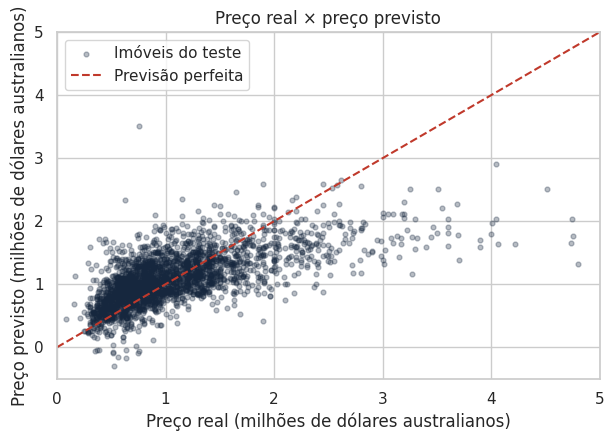

In [13]:
plt.scatter(y_teste / 1_000_000, y_prev / 1_000_000,   # x = preço real, y = previsto (em milhões)
            color=AZUL, alpha=0.3, s=12, label='Imóveis do teste')   # pontos transparentes
limite = [0, 5]                                        # intervalo da diagonal, em milhões
plt.plot(limite, limite, color=VERM, linestyle='--', label='Previsão perfeita')   # diagonal: previsto = real
plt.title('Preço real × preço previsto')               # título
plt.xlabel('Preço real (milhões de dólares australianos)')    # eixo x
plt.ylabel('Preço previsto (milhões de dólares australianos)')   # eixo y
plt.xlim(0, 5)                                         # limita o eixo x a 0-5 milhões
plt.ylim(-0.5, 5)                                      # limita o eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

# 🎯 Exercício 1 (5 min) — Qual o preço de um imóvel?

**Desafio:** use o `modelo_preco` para prever o preço de um imóvel com **4 quartos, 2 banheiros, 2 vagas, a 5 km do centro e 500 m² de terreno**.

In [14]:
# TODO: crie um DataFrame com as 5 colunas (na mesma ordem de colunas_x) e use modelo_preco.predict(...)

# 🏷️ Bloco 5 — KNN: imóvel caro ou barato? (20 min)

Agora, em vez de prever o **valor**, queremos **classificar** o imóvel em uma de duas categorias.

**Criando a classe:** chamaremos de **caro** (1) o imóvel com preço **acima da mediana** e **barato** (0) o resto. A **mediana** é o valor do meio: metade dos imóveis custa menos, metade custa mais. Assim as duas classes ficam **equilibradas** (≈ 50% cada).

Passos da Aula 2: separar X e y → dividir (`stratify`) → **padronizar** → escolher K → treinar → avaliar com matriz de confusão, precisão e recall.

> Atenção: o **preço não entra em X** (senão o modelo "colaria" a resposta!). X continua com as 5 características.

### Criando a coluna "caro"

Comparamos cada preço com a mediana: o resultado (verdadeiro/falso) vira 1 ou 0.

**🔍 Linha a linha**

- `df['preco'].median()`: a mediana dos preços.
- `(df['preco'] > mediana)`: verdadeiro quando o preço passa da mediana; `.astype(int)` converte verdadeiro/falso em 1/0.
- `df['caro'] = ...`: cria uma **nova coluna** na tabela.
- `.value_counts()`: conta os imóveis de cada classe (quase 50% / 50%).

In [15]:
mediana = df['preco'].median()                         # valor do meio dos preços
df['caro'] = (df['preco'] > mediana).astype(int)       # 1 se o preço está acima da mediana, 0 caso contrário

print(f'Mediana do preço: {mediana:,.0f} dólares')     # mostra a mediana
print(df['caro'].value_counts().sort_index().to_string())   # quantos imóveis em cada classe

Mediana do preço: 906,000 dólares
caro
0    6642
1    6641


### Separando, dividindo e padronizando

Os passos 1 a 3 da Aula 2.

**🔍 Linha a linha**

- `X` continua sendo as 5 colunas explicativas (definido no Bloco 4); só o **alvo** mudou.
- `stratify=y_caro`: mantém a proporção de caros e baratos no treino e no teste.
- `fit_transform` no treino e `transform` no teste: a regra de ouro da padronização (Aula 2).
- Padronizar é **essencial** aqui: o terreno (centenas) e os quartos (poucas unidades) têm escalas muito diferentes.

In [16]:
y_caro = df['caro']                                    # y = a nova classe (0 barato, 1 caro); X é o mesmo de antes

Xk_treino, Xk_teste, yk_treino, yk_teste = train_test_split(   # divide em treino e teste
    X, y_caro, test_size=0.25, random_state=42, stratify=y_caro)   # 25% teste; mesma proporção de classes

scaler_k = StandardScaler()                            # cria o padronizador
Xk_treino_pad = scaler_k.fit_transform(Xk_treino)      # aprende média/desvio no treino e padroniza o treino
Xk_teste_pad = scaler_k.transform(Xk_teste)            # padroniza o teste com os valores do treino
print('Imóveis no treino:', len(Xk_treino), '| no teste:', len(Xk_teste))   # tamanhos

Imóveis no treino: 9962 | no teste: 3321


### Escolhendo o K

O mesmo gráfico da Aula 2: acurácia no treino e no teste para cada K.

**🔍 Linha a linha**

- Mesmo laço da Aula 2: para cada K, treina e guarda as acurácias.
- `np.argmax(acc_teste)`: posição do maior valor; `list(valores_k)[posição]` converte a posição em K.
- `plt.axvline(melhor_k, ...)`: linha **v**ertical no melhor K.
- Leitura: com K pequeno há **overfitting** (treino alto, teste baixo); a partir de K ≈ 10 a curva do teste **estabiliza** em ≈ 80%. Qualquer K nessa faixa serve.

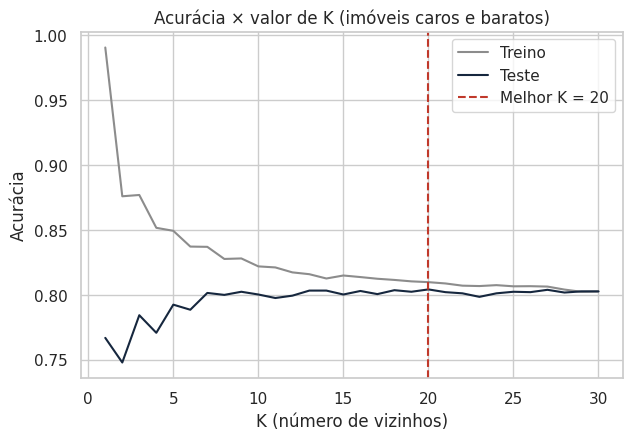

Melhor K: 20


In [17]:
valores_k = range(1, 31)                               # K de 1 até 30
acc_treino = []                                        # lista para a acurácia no treino
acc_teste = []                                         # lista para a acurácia no teste

for k in valores_k:                                    # repete para cada K
    knn_k = KNeighborsClassifier(n_neighbors=k)        # cria o KNN com esse K
    knn_k.fit(Xk_treino_pad, yk_treino)                # treina
    acc_treino.append(knn_k.score(Xk_treino_pad, yk_treino))   # acurácia no treino
    acc_teste.append(knn_k.score(Xk_teste_pad, yk_teste))      # acurácia no teste

melhor_k = list(valores_k)[int(np.argmax(acc_teste))]  # K com maior acurácia no teste
plt.plot(valores_k, acc_treino, color=CINZA, label='Treino')   # curva do treino
plt.plot(valores_k, acc_teste, color=AZUL, label='Teste')      # curva do teste
plt.axvline(melhor_k, color=VERM, linestyle='--', label=f'Melhor K = {melhor_k}')   # marca o melhor K
plt.title('Acurácia × valor de K (imóveis caros e baratos)')   # título
plt.xlabel('K (número de vizinhos)')                   # eixo x
plt.ylabel('Acurácia')                                 # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe
print('Melhor K:', melhor_k)                           # mostra o melhor K

### Treinando com o melhor K e avaliando

Matriz de confusão, precisão e recall da classe "caro".

**🔍 Linha a linha**

- `precision_score` e `recall_score`: como a classe de interesse ("caro") é a **1**, não precisamos de `pos_label` (veja a Aula 2).
- **Precisão:** dos imóveis que o modelo chamou de caros, que fração realmente era.
- **Recall:** dos imóveis realmente caros, que fração o modelo encontrou.
- `confusion_matrix`: linhas = classe real; colunas = classe prevista. A diagonal são os acertos.
- Leitura: acurácia em torno de 80%. Errar para os dois lados acontece em frequência parecida (≈ 10% cada).

Acurácia : 0.804
Precisão : 0.802
Recall   : 0.808


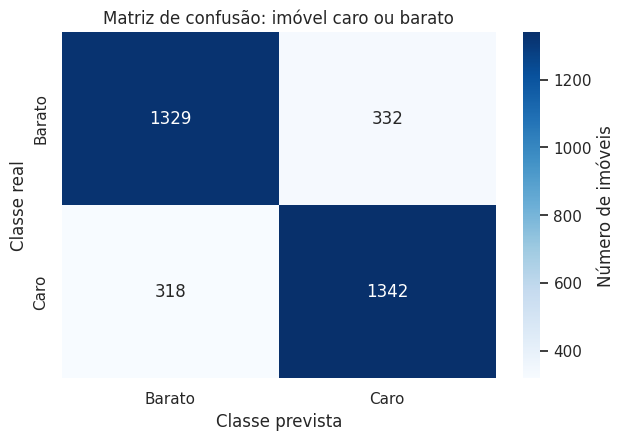

In [18]:
knn_final = KNeighborsClassifier(n_neighbors=melhor_k)     # KNN com o melhor K
knn_final.fit(Xk_treino_pad, yk_treino)                # treina
yk_prev = knn_final.predict(Xk_teste_pad)              # prevê no teste

print(f'Acurácia : {accuracy_score(yk_teste, yk_prev):.3f}')   # fração de acertos
print(f'Precisão : {precision_score(yk_teste, yk_prev):.3f}')  # dos que chamei de caro, quantos eram
print(f'Recall   : {recall_score(yk_teste, yk_prev):.3f}')     # dos caros reais, quantos encontrei

cm = confusion_matrix(yk_teste, yk_prev)               # matriz de confusão
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',     # heatmap com os números inteiros
            xticklabels=['Barato', 'Caro'], yticklabels=['Barato', 'Caro'],   # nomes das classes
            cbar_kws={'label': 'Número de imóveis'})   # legenda da barra
plt.title('Matriz de confusão: imóvel caro ou barato')     # título
plt.xlabel('Classe prevista')                          # eixo x
plt.ylabel('Classe real')                              # eixo y
plt.show()                                             # exibe

# 🎯 Exercício 2 (5 min) — O imóvel do exercício 1 é caro?

**Desafio:** use o `knn_final` para classificar o mesmo imóvel do exercício 1 (**4 quartos, 2 banheiros, 2 vagas, 5 km, 500 m²**). Mostre a classe e a proporção de vizinhos "caros". Lembre-se de **padronizar** o imóvel com o `scaler_k`.

In [19]:
# TODO: crie o DataFrame, padronize com scaler_k.transform(...) e use knn_final.predict / predict_proba

# 🧩 Bloco 6 — PCA + K-means: perfis de imóveis (20 min)

**Pergunta:** os imóveis formam **grupos naturais** (perfis)? Aqui **não usamos o preço nem a classe "caro"**: agrupamos apenas pelas **características** (quartos, banheiros, vagas, distância, terreno). Depois, **interpretamos** os grupos olhando seu perfil médio e, por fim, o preço médio de cada um.

Roteiro (Aula 3): **padronizar → PCA (para enxergar em 2D) → cotovelo → K-means → perfil dos grupos**.

### Padronizando e aplicando o PCA

Resumimos as 5 características em 2 componentes para poder desenhar os imóveis.

**🔍 Linha a linha**

- `StandardScaler().fit_transform(X)`: padroniza (aqui todo o conjunto, pois não há teste).
- `PCA(n_components=2).fit_transform(...)`: reduz de 5 para 2 colunas.
- `pca.components_`: pesos das variáveis em cada componente.
- Leitura: as 2 PCs guardam ≈ 67% da informação. A **PC1** tem pesos positivos em todas as variáveis de "tamanho" (quartos, banheiros, vagas, terreno): funciona como um índice de **porte do imóvel**. A **PC2** contrasta a **distância** (positiva) com os **banheiros** (negativa).

In [20]:
X_pad = StandardScaler().fit_transform(X)              # padroniza as 5 características (todos os imóveis)
pca = PCA(n_components=2)                              # PCA com 2 componentes
pcs = pca.fit_transform(X_pad)                         # converte cada imóvel para (PC1, PC2)

print('Variância explicada:', pca.explained_variance_ratio_.round(3))   # fração de cada componente
print(f'As 2 primeiras PCs guardam {pca.explained_variance_ratio_.sum()*100:.1f}% da informação')   # soma
pesos = pd.DataFrame(pca.components_, columns=colunas_x, index=['PC1', 'PC2'])   # pesos de cada variável
print(pesos.round(2))                                  # mostra os pesos

Variância explicada: [0.476 0.198]
As 2 primeiras PCs guardam 67.4% da informação
     quartos  banheiros  vagas  distancia_km  terreno_m2
PC1     0.54       0.43   0.44          0.35        0.45
PC2    -0.27      -0.61   0.02          0.64        0.38


### Escolhendo o número de grupos (cotovelo)

Calculamos a inércia do K-means para K de 1 a 8.

**🔍 Linha a linha**

- Mesmo código da Aula 3.
- Leitura: em dados reais o "cotovelo" é **suave**, não nítido como nos dados sintéticos. A queda é grande até K = 3 e fica gradual depois. Escolhemos **K = 3** por ser um bom compromisso entre simplicidade e detalhe (e por permitir uma interpretação clara).

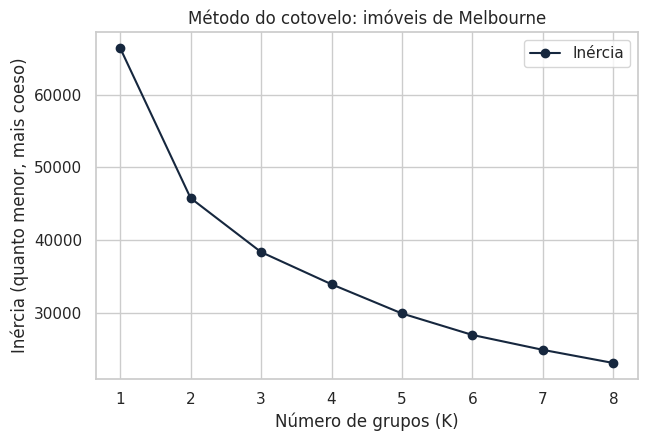

In [21]:
valores_k = range(1, 9)                                # K de 1 até 8
inercias = []                                          # lista para as inércias

for k in valores_k:                                    # repete para cada K
    km = KMeans(n_clusters=k, n_init=10, random_state=42)   # cria o K-means
    km.fit(X_pad)                                      # aprende os grupos
    inercias.append(km.inertia_)                       # guarda a inércia

plt.plot(valores_k, inercias, color=AZUL, marker='o', label='Inércia')   # linha com bolinhas
plt.title('Método do cotovelo: imóveis de Melbourne')  # título
plt.xlabel('Número de grupos (K)')                     # eixo x
plt.ylabel('Inércia (quanto menor, mais coeso)')       # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### K-means com K = 3 e o perfil dos grupos

O mais importante em clusterização é **interpretar** o resultado: qual o perfil médio de cada grupo?

**🔍 Linha a linha**

- `km_final.fit_predict(X_pad)`: aprende os grupos e devolve o grupo (0, 1 ou 2) de cada imóvel; guardamos na coluna `grupo`.
- `df.groupby('grupo')[colunas].mean()`: **agrupa** as linhas por grupo e calcula a **média** de cada coluna em cada grupo.
- `colunas_x + ['preco']`: junta duas listas. Incluímos o preço **só para interpretar** (ele não foi usado para formar os grupos).
- `.value_counts().sort_index()`: número de imóveis de cada grupo, em ordem de grupo.

In [22]:
km_final = KMeans(n_clusters=3, n_init=10, random_state=42)   # K-means com 3 grupos
df['grupo'] = km_final.fit_predict(X_pad)              # grupo de cada imóvel, guardado em nova coluna

perfil = df.groupby('grupo')[colunas_x + ['preco']].mean().round(1)   # média de cada variável, por grupo
perfil['n_imoveis'] = df['grupo'].value_counts().sort_index()         # quantos imóveis em cada grupo
print(perfil.to_string())                              # mostra a tabela de perfil

       quartos  banheiros  vagas  distancia_km  terreno_m2      preco  n_imoveis
grupo                                                                           
0          3.8        2.3    2.2          12.6       573.6  1408760.1       4563
1          2.9        1.0    1.8          12.1       651.0   959905.4       3568
2          2.3        1.2    1.0           6.7       143.3   868808.1       5152


### 🗣️ Interpretando os grupos

Olhando a tabela de perfil (as etiquetas 0, 1 e 2 são arbitrárias; descreva pelo **perfil**):

| Perfil | Características médias | Preço médio |
|---|---|---|
| **Casas grandes** | ≈ 3,8 quartos, 2,3 banheiros, 2,2 vagas, terreno ≈ 570 m² | **≈ 1,41 milhão** (o mais caro) |
| **Casas médias, 1 banheiro** | ≈ 2,9 quartos, 1 banheiro, 1,8 vaga, terreno ≈ 650 m² | ≈ 0,96 milhão |
| **Apartamentos/imóveis compactos perto do centro** | ≈ 2,3 quartos, terreno ≈ 143 m², a ≈ 6,7 km do centro | ≈ 0,87 milhão |

O K-means **descobriu perfis coerentes** sem nunca ver o preço, e os preços médios dos grupos são bem diferentes. Isso é uma **segmentação** do mercado.

### Mapa dos grupos e preço médio

À esquerda, os imóveis no mapa do PCA, coloridos pelo grupo. À direita, o preço médio de cada grupo.

**🔍 Linha a linha**

- `(df['grupo'] == g).values`: lista de verdadeiro/falso marcando os imóveis do grupo `g`.
- `pcs[marcador, 0]`: PC1 só dos imóveis marcados; assim cada grupo recebe sua cor.
- `df.groupby('grupo')['preco'].mean()`: preço médio de cada grupo.
- `eixos[1].bar(...)`: gráfico de barras no segundo painel.
- Leitura: os grupos ocupam regiões diferentes do mapa, e o grupo de "casas grandes" tem o maior preço médio.

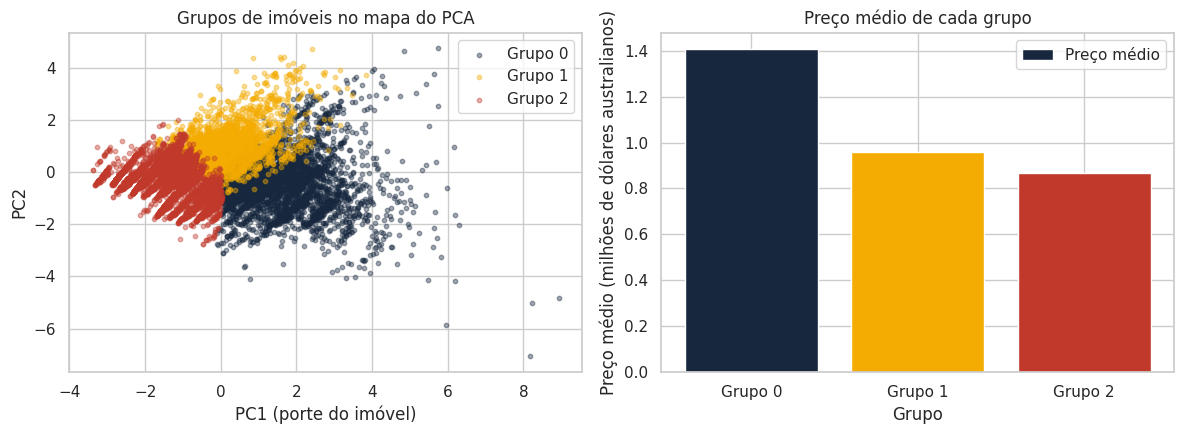

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))      # 2 gráficos lado a lado
cores_grupos = [AZUL, OURO, VERM]                       # uma cor por grupo

for g in [0, 1, 2]:                                     # para cada grupo
    marcador = (df['grupo'] == g).values                # True para os imóveis desse grupo
    eixos[0].scatter(pcs[marcador, 0], pcs[marcador, 1],   # PC1 (x) e PC2 (y) desses imóveis
                     color=cores_grupos[g], alpha=0.4, s=10, label=f'Grupo {g}')   # cor, transparência e legenda
eixos[0].set_title('Grupos de imóveis no mapa do PCA')  # título 1
eixos[0].set_xlabel('PC1 (porte do imóvel)')            # eixo x
eixos[0].set_ylabel('PC2')                              # eixo y
eixos[0].legend()                                       # legenda

preco_medio = df.groupby('grupo')['preco'].mean() / 1_000_000   # preço médio por grupo, em milhões
eixos[1].bar(['Grupo 0', 'Grupo 1', 'Grupo 2'], preco_medio.values, color=cores_grupos, label='Preço médio')   # barras
eixos[1].set_title('Preço médio de cada grupo')         # título 2
eixos[1].set_xlabel('Grupo')                            # eixo x
eixos[1].set_ylabel('Preço médio (milhões de dólares australianos)')   # eixo y
eixos[1].legend()                                       # legenda
plt.tight_layout()                                      # evita sobreposição
plt.show()                                              # exibe

# 🎯 Exercício 3 (10 min) — Quatro grupos

**Desafio:** rode o K-means com **K = 4** sobre `X_pad`, guarde em uma nova coluna `grupo4` e mostre, para cada grupo, o **número de imóveis** e a **média** de quartos, distância, terreno e preço. Descreva em uma frase o perfil de cada grupo.

In [24]:
# TODO: KMeans(n_clusters=4, n_init=10, random_state=42); depois df.groupby('grupo4')[['quartos', 'distancia_km', 'terreno_m2', 'preco']].mean()

# 🏁 Bloco 7 — Fechamento (5 min)

## O que fizemos

| Etapa | Técnica | Resultado |
|---|---|---|
| Limpeza | `dropna`, filtro de outliers | de 13.580 para ≈ 13.280 imóveis |
| Regressão | `LinearRegression` | R² ≈ 0,43; erro médio ≈ 338 mil |
| Classificação | KNN com padronização | acurácia ≈ 80% (caro × barato) |
| Agrupamento | PCA + K-means (K = 3) | 3 perfis de imóveis |

## Como ler cada resultado (roteiro de interpretação)

| Resultado | Pergunta para se fazer |
|---|---|
| **Coeficientes** da regressão | Qual o sinal (sobe ou desce o preço)? Qual a unidade? Lembre: "mantendo as outras variáveis fixas". |
| **R²** | Que fração da variação do preço o modelo explica? (0,43 = menos da metade: sobra muita coisa de fora) |
| **MAE / RMSE** | Esse erro, **na unidade do problema**, é aceitável para quem vai usar a previsão? |
| **Acurácia** do KNN | É bem melhor que o palpite de referência (≈ 50%)? |
| **Matriz de confusão** | Em que lado o modelo mais erra: chama de caro o que é barato, ou o contrário? |
| **Cotovelo** | Onde a queda da inércia passa a ser pequena? |
| **Perfil dos grupos** | Em que as médias de cada grupo diferem? Dá para dar um nome a cada grupo? |

## Como levar para o **seu** projeto
1. **Carregue** o seu CSV com `pd.read_csv`.
2. **Selecione** as colunas e **trate** ausentes e extremos (mostre quantas linhas perdeu).
3. **Explore** com `describe`, histograma e heatmap.
4. Escolha a técnica pela **pergunta**:
   - prever um **número** → regressão;
   - prever uma **categoria** → KNN (ou outro classificador);
   - descobrir **grupos** → PCA + K-means.
5. **Interprete** sempre: coeficientes, métricas, perfis dos grupos.

## Ideias para melhorar este projeto
- Incluir variáveis **categóricas** (tipo do imóvel, região) transformando-as em colunas 0/1.
- Usar outras colunas (`BuildingArea`, `YearBuilt`) tratando os ausentes de outra forma.
- Testar outros valores de K e outros limites para os outliers.

> O **Guia de Receitas** traz a estrutura mínima de cada técnica, pronta para adaptar.

## 📝 Tarefa para casa
Troque a definição de "caro" por **preço acima do 3º quartil** (`df['preco'].quantile(0.75)`). O que acontece com o **recall** do KNN, agora que a classe "caro" é bem mais rara?

# ✅ Gabarito dos exercícios

Respostas de todos os exercícios deste notebook. **Tente resolver antes de olhar!**

> As soluções abaixo são texto (não executam): copie o código para uma célula se quiser rodar.

## 🎯 Exercício 1 (5 min) — Qual o preço de um imóvel?

**Resposta (saída esperada):**

```text
Preço previsto: 1,686,736 dólares
```

**Código da solução:**

```python
imovel = pd.DataFrame({'quartos': [4], 'banheiros': [2], 'vagas': [2], 'distancia_km': [5], 'terreno_m2': [500]})   # novo imóvel
print(f'Preço previsto: {modelo_preco.predict(imovel)[0]:,.0f} dólares')   # previsão
```

## 🎯 Exercício 2 (5 min) — O imóvel do exercício 1 é caro?

**Resposta (saída esperada):**

```text
Classe prevista: Caro
Proporção de vizinhos caros: 1.00
```

**Código da solução:**

```python
imovel2 = pd.DataFrame({'quartos': [4], 'banheiros': [2], 'vagas': [2], 'distancia_km': [5], 'terreno_m2': [500]})   # novo imóvel
imovel2_pad = scaler_k.transform(imovel2)              # padroniza com o scaler do treino
classe = knn_final.predict(imovel2_pad)[0]             # classe prevista
prob_caro = knn_final.predict_proba(imovel2_pad)[0, 1] # proporção de vizinhos caros
print('Classe prevista:', ['Barato', 'Caro'][classe])  # traduz o código
print(f'Proporção de vizinhos caros: {prob_caro:.2f}') # proporção
```

## 🎯 Exercício 3 (10 min) — Quatro grupos

**Resposta:** Perfis possíveis: grupo 0 (≈ 900 imóveis) = distantes do centro (≈ 25 km) e mais baratos; grupo 1 = intermediário (≈ 11 km, preço médio ≈ 990 mil); grupo 2 = imóveis pequenos e próximos do centro (terreno ≈ 130 m², provavelmente apartamentos); grupo 3 = casas grandes (≈ 3,8 quartos) e as mais caras (≈ 1,5 milhão). Para descrever, compare a média de cada coluna entre os grupos.

**Código da solução:**

```python
km4 = KMeans(n_clusters=4, n_init=10, random_state=42)   # K-means com 4 grupos
df['grupo4'] = km4.fit_predict(X_pad)                   # grupo de cada imóvel
resumo4 = df.groupby('grupo4').agg(imoveis=('preco', 'count'), quartos=('quartos', 'mean'),
                                   distancia_km=('distancia_km', 'mean'), terreno_m2=('terreno_m2', 'mean'),
                                   preco=('preco', 'mean')).round(1)   # tamanho e perfil médio de cada grupo
print(resumo4.to_string())                              # mostra o resumo
```